# 5. Experimento 4 – Mudança de conceito e retreinamento (Base A)

**Projeto:** Agente Identificador de Fraudes Bancárias  
**Disciplina:** Inteligência Artificial – 7º semestre – Ciência da Computação  
**Instituição:** Universidade Presbiteriana Mackenzie – Faculdade de Computação e Informática  
**Professor:** Prof. Dr. Ivan Carlos Alcântara de Oliveira

| Integrante | RA | E-mail |
|---|---|---|
| Cheuk Ki Yu | 10419664 | cheuk.yu@mackenzista.com.br |
| Gabriela Nellessen de Sousa | 10441930 | gabrielanellessen@gmail.com |
| Milton Almeida Leoncio | 10416764 | milton.almeida@live.com |

**Síntese:** Avaliação mês a mês em 2019 de três estratégias: treino até 2016, treino na janela recente e retreino mensal com janela deslizante.

**Histórico de alterações**

| Data | Autor | Descrição |
|---|---|---|
| 2026-10-28 | Milton Almeida Leoncio | Versão inicial da etapa nos resultados preliminares (N1) |
| 2026-11-20 | Milton Almeida Leoncio | Versão final do projeto (N2) |

In [1]:
# ========================================================================================
# Projeto: Agente Identificador de Fraudes Bancárias
# Disciplina: Inteligência Artificial - 7º semestre - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática (FCI)
# Professor: Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrantes:
#   Cheuk Ki Yu                  - RA 10419664 - cheuk.yu@mackenzista.com.br
#   Gabriela Nellessen de Sousa  - RA 10441930 - gabrielanellessen@gmail.com
#   Milton Almeida Leoncio       - RA 10416764 - milton.almeida@live.com
# Arquivo: notebooks/05_mudanca_de_conceito.ipynb
# Síntese: Avaliação mês a mês em 2019 de três estratégias: treino até 2016, treino na janela recente e retreino mensal com janela deslizante.
# Histórico de alterações:
#   2026-10-28 - Milton Almeida Leoncio - Versão inicial da etapa nos resultados preliminares (N1)
#   2026-11-20 - Milton Almeida Leoncio - Versão final do projeto (N2)
# ========================================================================================

import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
os.environ.setdefault('FRAUDES_ATRIBUTOS', str(RAIZ / 'atributos'))  # saída de preparar_bases.py
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = RAIZ / 'resultados'

Supõe-se que os rótulos de um mês estejam disponíveis ao fim dele. No retreino mensal, cada modelo usa os 21 meses anteriores ao mês avaliado; os 3 últimos servem de validação para a parada antecipada e o limiar.

In [2]:
import exp4_drift as e4
mensal, total = e4.executar()
total

,estrategia,n,fraudes,tp,fp,fn,precision,recall,f1,pr_auc
0,Estático (histórico até 2016),1723938,2087,388,1660,1699,0.189,0.186,0.188,0.121
1,Estático (janela recente),1723938,2087,1400,565,687,0.712,0.671,0.691,0.759
2,Retreino mensal,1723938,2087,1524,578,563,0.725,0.730,0.728,0.784


In [3]:
mensal.pivot(index='mes', columns='estrategia', values='f1')

estrategia,Estático (histórico até 2016),Estático (janela recente),Retreino mensal
mes,,,
2019-01,0.214,0.754,0.754
2019-02,0.226,0.714,0.703
2019-03,0.187,0.718,0.737
2019-04,0.209,0.744,0.726
2019-05,0.257,0.748,0.780
2019-06,0.216,0.616,0.687
2019-07,0.152,0.647,0.692
2019-08,0.208,0.700,0.784
2019-09,0.145,0.625,0.703


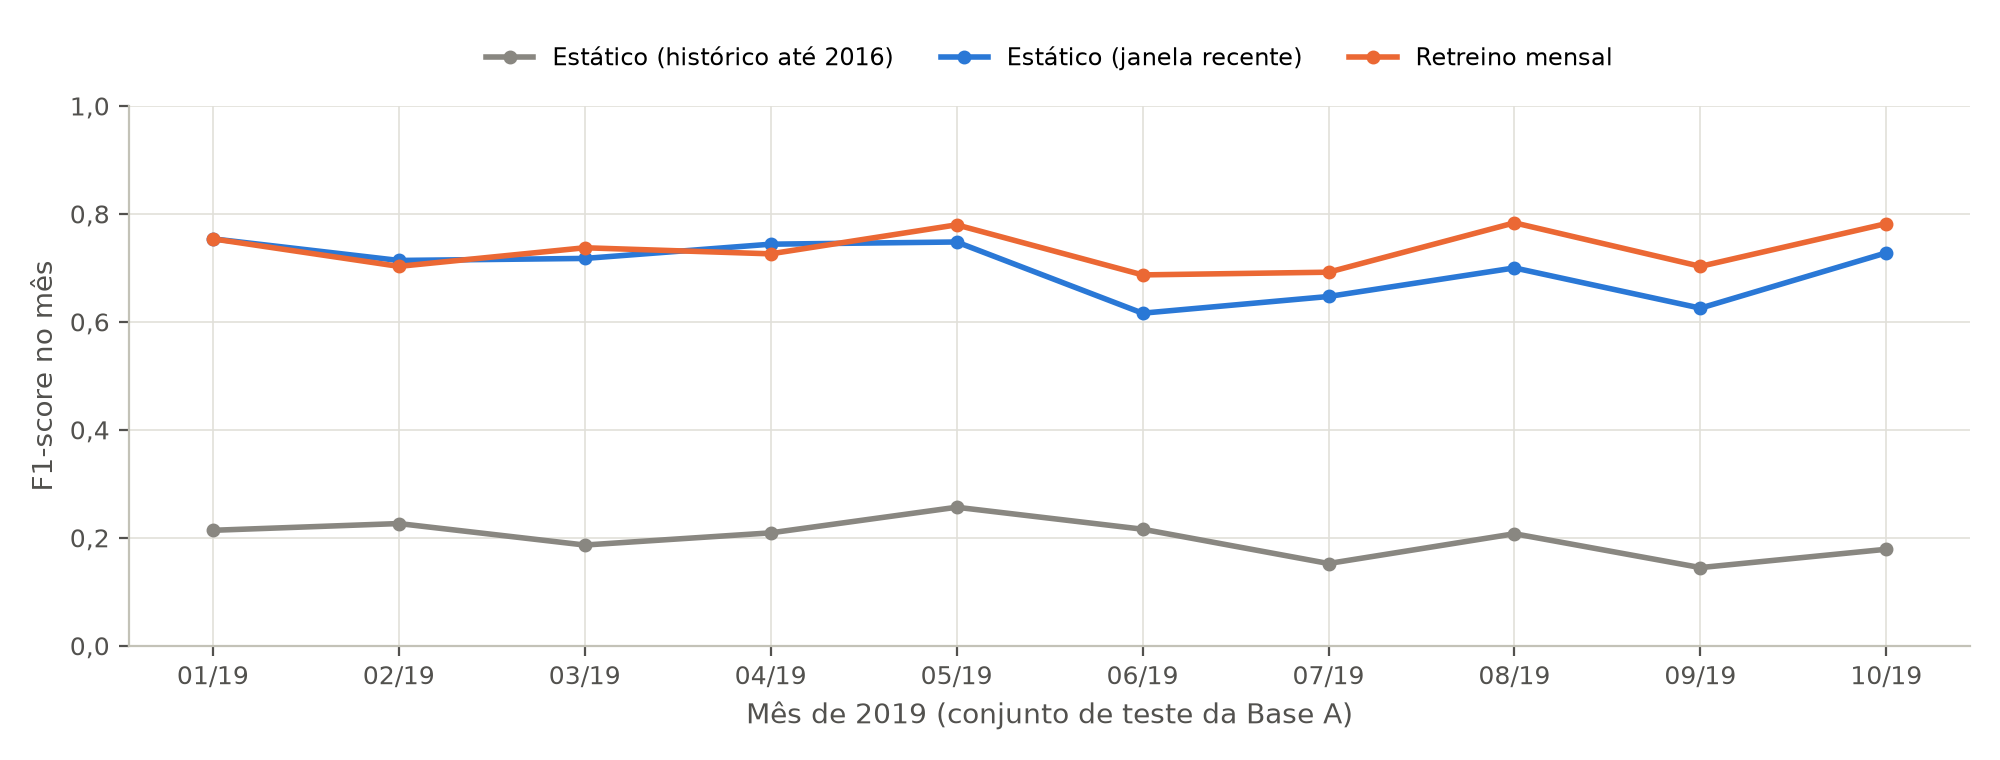

In [4]:
e4.figura()
display(Image(FIG / 'fig_exp4_drift_mensal.png', width=1000))

**Leitura dos resultados.** Treinado só com o padrão antigo (fraudes online), o modelo quase não detecta as fraudes de 2019, que são compras no exterior. O retreino mensal supera o modelo estático na maioria dos meses, principalmente no segundo semestre. Novembro e dezembro de 2019 não têm fraudes rotuladas.